In [11]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import mean_squared_error

Размер: 626×626, каналов: 3


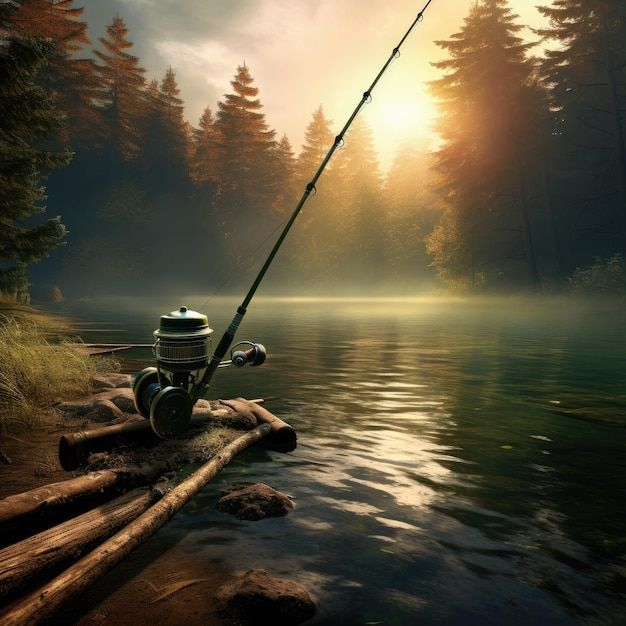

In [12]:
IMAGE_PATH = "/content/fishingg.png"
img = Image.open(IMAGE_PATH).convert("RGB")
img_rgb = np.array(img)
h, w, c = img_rgb.shape
original_shape = img_rgb.shape
original_flat = img_rgb.flatten()

print(f"Размер: {w}×{h}, каналов: {c}")
img

In [18]:
R, G, B = img_rgb[:,:,0], img_rgb[:,:,1], img_rgb[:,:,2]
U_R, s_R, Vt_R = np.linalg.svd(R, full_matrices=False)
U_G, s_G, Vt_G = np.linalg.svd(G, full_matrices=False)
U_B, s_B, Vt_B = np.linalg.svd(B, full_matrices=False)

In [26]:

list_of_ranks = [1, 5, 10, 30, 100, min(h, w)]
approximations = []
compression_ratios = []
original_size = h * w * 3

for r in list_of_ranks:

    R_r = (U_R[:, :r] * s_R[:r]) @ Vt_R[:r, :]
    G_r = (U_G[:, :r] * s_G[:r]) @ Vt_G[:r, :]
    B_r = (U_B[:, :r] * s_B[:r]) @ Vt_B[:r, :]

    img_r = np.clip(np.stack([R_r, G_r, B_r], axis=-1), 0, 255)
    approximations.append(img_r)


    compressed_size = 3 * r * (h + 1 + w) * 4
    ratio = original_size / compressed_size
    compression_ratios.append(ratio)


    mse = np.mean((img_rgb.astype(float) - img_r.astype(float))**2)

    print(f"r={r:3d} | Сжатие: {ratio:5.1f}x | MSE: {mse:.1f}")


r=  1 | Сжатие:  78.2x | MSE: 1024.2
r=  5 | Сжатие:  15.6x | MSE: 472.4
r= 10 | Сжатие:   7.8x | MSE: 310.1
r= 30 | Сжатие:   2.6x | MSE: 130.3
r=100 | Сжатие:   0.8x | MSE: 31.4
r=626 | Сжатие:   0.1x | MSE: 0.0


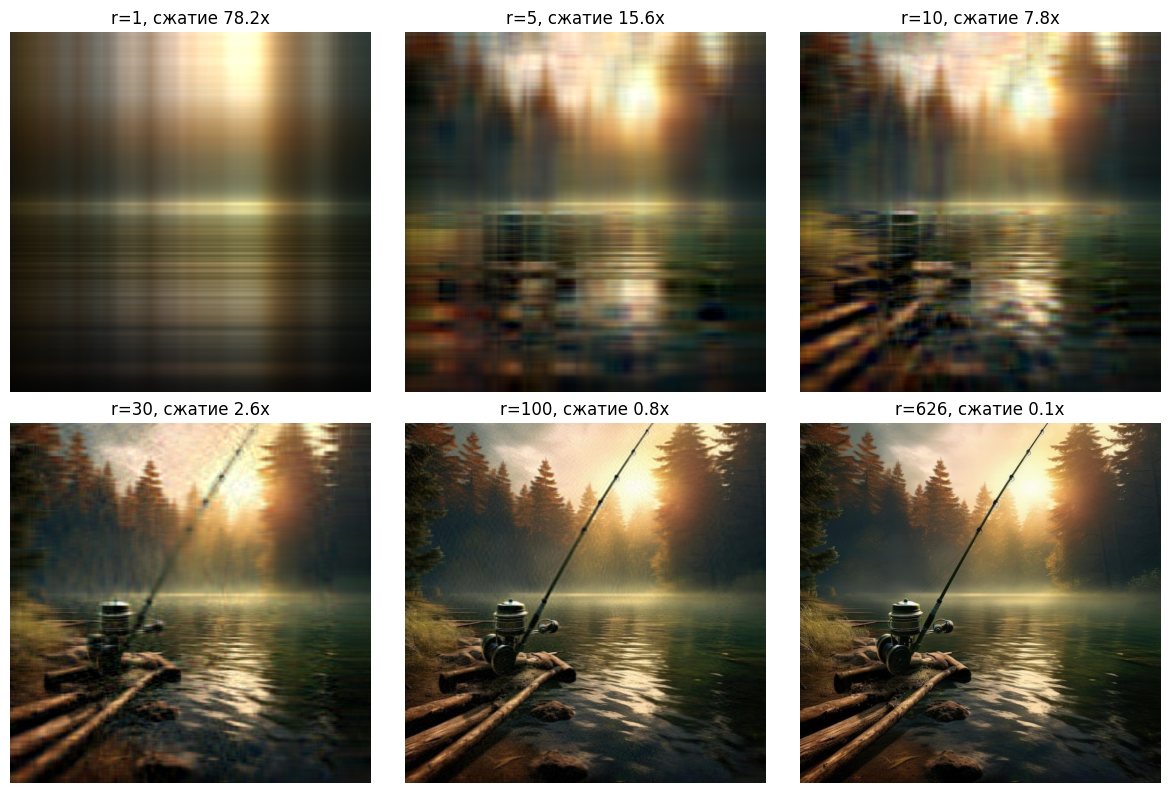

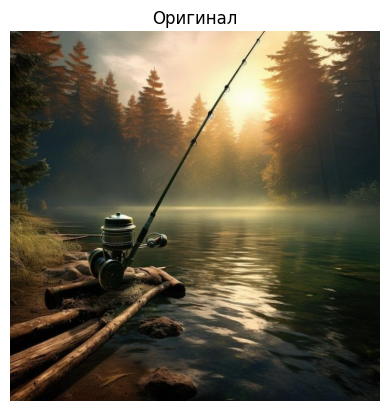

In [27]:

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i, (r, img_r, ratio) in enumerate(zip(list_of_ranks, approximations, compression_ratios)):
    axes[i//3, i%3].imshow(img_r.astype(np.uint8))
    axes[i//3, i%3].set_title(f"r={r}, сжатие {ratio:.1f}x")
    axes[i//3, i%3].axis('off')
plt.tight_layout()
plt.show()


plt.imshow(img_rgb)
plt.title("Оригинал")
plt.axis('off')
plt.show()

In [28]:

print("\nЗапуск автопроверки...")
original_flat = img_rgb.flatten()

for i, r in enumerate(list_of_ranks):

    assert approximations[i].shape == original_shape, f"Ошибка размерности для r={r}"


    arr = approximations[i]
    assert arr.max() <= 255.1, f"Значения > 255 для r={r}"
    assert arr.min() >= -0.1, f"Значения < 0 для r={r}"


mse_list = []
for i in range(len(approximations)):

    mse = np.mean((original_flat.astype(float) - approximations[i].flatten().astype(float))**2)
    mse_list.append(mse)

for i in range(1, len(mse_list)):
    assert mse_list[i] <= mse_list[i-1] + 1e-6, f"MSE не уменьшается между r={list_of_ranks[i-1]} и r={list_of_ranks[i]}"

print("Все автоматические проверки пройдены.")


Запуск автопроверки...
Все автоматические проверки пройдены.
